# Machine learning and analytics


In [8]:
import os, sys, re, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Paths
PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / "data" / "raw").is_dir() and (p / "src").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the project root or its notebook folder before running.")
RAW_DIR   = PROJECT_ROOT / "data" / "raw"
PROC_DIR  = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MLRUNS_DIR = PROJECT_ROOT / "mlruns"
for d in (RAW_DIR, PROC_DIR, MODEL_DIR, MLRUNS_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from text_preprocessing import (clean_text, preprocess_corpus, split_sentences,
                                strip_connectors, normalise_unicode, LEVELS, STOP_WORDS)

# Run configuration
SEED = 42
# Pre-trained transformer used for topic embeddings and for the fine-tuned classifier:
# a Hugging Face model id, or a local folder containing a saved model.
TRANSFORMER_MODEL = os.getenv("MONTRA_TRANSFORMER", "roberta-base")
TRANSFORMER_LABEL = "RoBERTa-base" if "roberta" in TRANSFORMER_MODEL.lower() else Path(TRANSFORMER_MODEL).name
EMBEDDING_BACKEND = "auto"     # "auto": cached → sentence-transformers (all-MiniLM-L6-v2) → TRANSFORMER_MODEL mean-pooled → TF-IDF + SVD
RUN_BERT = "auto"              # "auto": fine-tune only if no saved results exist | True: always retrain | False: never train
WRITE_OUTPUTS_TO_DB = False    # also write model outputs to a separate Postgres table

np.random.seed(SEED)
NOTEBOOK_START = pd.Timestamp.now(tz="UTC")   # used to summarise this execution's MLflow runs
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
SENT_ORDER  = ["negative", "neutral", "positive"]
SENT_COLORS = {"negative": "#C8553D", "neutral": "#B9B9B9", "positive": "#2A9D8F"}
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 120)
print("Project root:", PROJECT_ROOT)
from IPython.display import display
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(exist_ok=True)

import mlflow
TRACKING_URI = f"sqlite:///{(MLRUNS_DIR / 'mlflow.db').as_posix()}"
mlflow.set_tracking_uri(TRACKING_URI)
def use_experiment(name):
    exp = mlflow.get_experiment_by_name(name)
    if exp is None:
        mlflow.create_experiment(name, artifact_location=(MLRUNS_DIR / "artifacts" / name).resolve().as_uri())
    mlflow.set_experiment(name)

ML_N_JOBS = int(os.getenv("MONTRA_N_JOBS", "1"))  # increase only when memory permits


Project root: D:\Amdari\Project_montra


In [9]:
import joblib
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
def eval_metrics(y_true, y_pred, prefix=""):
    m = {"accuracy": accuracy_score(y_true, y_pred),
         "precision_macro": precision_score(y_true, y_pred, average="macro"),
         "recall_macro": recall_score(y_true, y_pred, average="macro"),
         "f1_macro": f1_score(y_true, y_pred, average="macro")}
    for s, v in zip(SENT_ORDER, f1_score(y_true, y_pred, labels=SENT_ORDER, average=None)):
        m[f"f1_{s}"] = v
    return {prefix + k: float(v) for k, v in m.items()}
def map_aspect(word_weights):
    """Score a topic against the business-aspect lexicon using its c-TF-IDF word weights."""
    scores = dict.fromkeys(ASPECT_LEXICON, 0.0)
    for w, wt in word_weights:
        for tok in w.split():
            for a, lex in ASPECT_LEXICON.items():
                if tok in lex:
                    scores[a] += wt
    total = sum(scores.values())
    best = max(scores, key=scores.get)
    return (best, scores[best] / total) if total > 0 else ("Other", 0.0)
def business_aspect(a):
    return ASPECT_GROUP.get(a, a)
handoff = MODEL_DIR / 'phase7_handoff.joblib'
if not handoff.exists():
    raise FileNotFoundError('Run bert.ipynb through its final save cell first.')
state = joblib.load(handoff)
globals().update(state)
import hashlib
current_corpus = pd.read_csv(PROC_DIR / 'nlp_corpus.csv')
signature = hashlib.sha256(pd.util.hash_pandas_object(
    current_corpus[['review_id', 'review_text', 'sentiment_label']], index=False).values.tobytes()).hexdigest()
if signature != data_signature:
    raise ValueError('Cleaning outputs changed since Phase 7. Rerun bert.ipynb.')
BERT_SAVE_DIR = MODEL_DIR / 'bert_sentiment'
BERT_RESULTS_PATH = PROC_DIR / 'bert_results.json'
class SavedTopicLookup:
    def get_topic(self, t):
        return topic_lookup.get(int(t), [])
topic_model = SavedTopicLookup()
exec(compile((PROJECT_ROOT / 'src' / 'bert_training_definitions.py').read_text(),
             'bert_training_definitions.py', 'exec'), globals())
use_experiment('montra-sentiment')
print('Loaded Phase 7 handoff:', len(reviews_clean), 'reviews;', len(sentences), 'sentences.')


Loaded Phase 7 handoff: 35000 reviews; 85829 sentences.


Here the goal is to systematically compare preprocessing strategies, feature representations, model architectures, hyperparameters, sequence length and epochs under one consistent validation procedure, and understand where models fail. Every run below is logged to the `montra-sentiment` MLflow experiment.

### 1.1 Experiment grid: preprocessing × feature representation × model

- **Preprocessing:** `minimal` (lowercase only), `standard` (+ contraction expansion keeping "not", punctuation removal), `aggressive` (+ stop-word removal, which also deletes *not / no / never*)
- **Features:** TF-IDF word unigrams, word 1–2-grams, character 2–5-grams
- **Models:** Logistic Regression, Multinomial Naive Bayes, Linear SVM

That makes 27 configurations, each scored by **3-fold stratified cross-validation on the training set** (macro-F1) and on the validation set.

Grid minimal | word_1gram | Logistic Regression: CV macro-F1=0.9413
Grid minimal | word_1gram | Naive Bayes: CV macro-F1=0.9317
Grid minimal | word_1gram | Linear SVM: CV macro-F1=0.9409
Grid minimal | word_1-2gram | Logistic Regression: CV macro-F1=0.9391
Grid minimal | word_1-2gram | Naive Bayes: CV macro-F1=0.9310
Grid minimal | word_1-2gram | Linear SVM: CV macro-F1=0.9395
Grid minimal | char_2-5gram | Logistic Regression: CV macro-F1=0.9411
Grid minimal | char_2-5gram | Naive Bayes: CV macro-F1=0.9319
Grid minimal | char_2-5gram | Linear SVM: CV macro-F1=0.9412
Grid standard | word_1gram | Logistic Regression: CV macro-F1=0.9411
Grid standard | word_1gram | Naive Bayes: CV macro-F1=0.9310
Grid standard | word_1gram | Linear SVM: CV macro-F1=0.9409
Grid standard | word_1-2gram | Logistic Regression: CV macro-F1=0.9389
Grid standard | word_1-2gram | Naive Bayes: CV macro-F1=0.9309
Grid standard | word_1-2gram | Linear SVM: CV macro-F1=0.9394
Grid standard | char_2-5gram | Logistic R

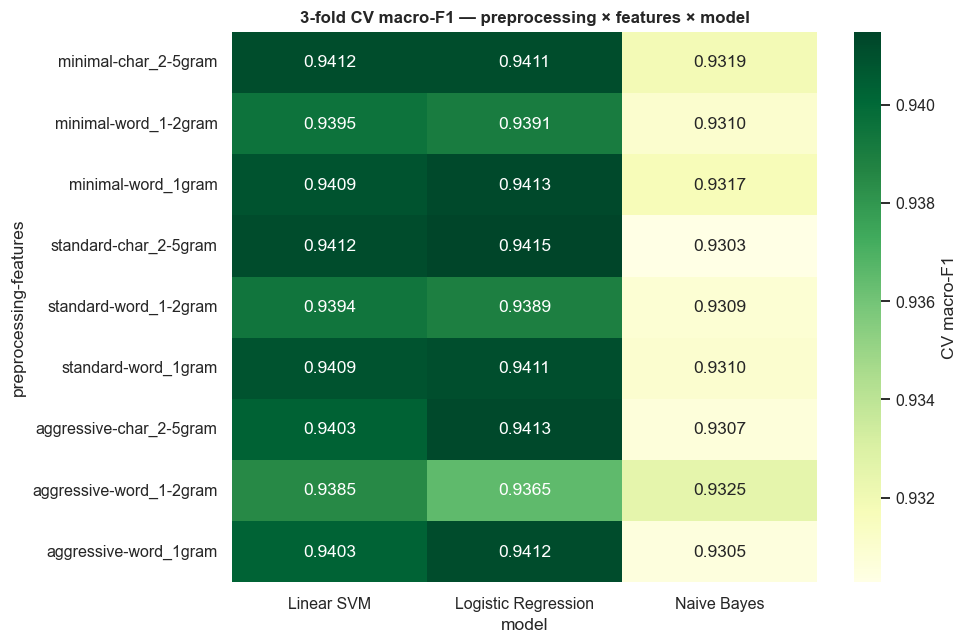

,preprocessing,features,model,cv_f1_macro,cv_std,val_f1_macro,val_f1_neutral
15,standard,char_2-5gram,Logistic Regression,0.9415,0.0026,0.9403,0.9217
0,minimal,word_1gram,Logistic Regression,0.9413,0.0025,0.9407,0.9222
24,aggressive,char_2-5gram,Logistic Regression,0.9413,0.0022,0.9403,0.9217
18,aggressive,word_1gram,Logistic Regression,0.9412,0.0026,0.9399,0.9212
17,standard,char_2-5gram,Linear SVM,0.9412,0.0027,0.9402,0.9217
8,minimal,char_2-5gram,Linear SVM,0.9412,0.0028,0.9397,0.9211
6,minimal,char_2-5gram,Logistic Regression,0.9411,0.0026,0.9401,0.9214
9,standard,word_1gram,Logistic Regression,0.9411,0.0026,0.9403,0.9217


,mean,max
preprocessing,,
minimal,0.9375,0.9413
standard,0.9372,0.9415
aggressive,0.9369,0.9413


In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
FEATURES = {
    "word_1gram":  dict(analyzer="word", ngram_range=(1, 1), min_df=2),
    "word_1-2gram": dict(analyzer="word", ngram_range=(1, 2), min_df=2),
    "char_2-5gram": dict(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=150_000),
}
MODELS = {"Logistic Regression": lambda: LogisticRegression(max_iter=3000, C=4, class_weight="balanced"),
          "Naive Bayes": lambda: MultinomialNB(alpha=0.5),
          "Linear SVM": lambda: LinearSVC(C=0.5, class_weight="balanced")}
texts = {lvl: {"train": preprocess_corpus(train_df["review_text"], lvl), "val": preprocess_corpus(val_df["review_text"], lvl)}
         for lvl in LEVELS}
grid_rows = []
t_grid = time.time()
for lvl in LEVELS:
    for fname, fparams in FEATURES.items():
        for mname, mk in MODELS.items():
            pipe = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True, **fparams)), ("clf", mk())])
            cv_scores = cross_val_score(pipe, texts[lvl]["train"], train_df["sentiment_label"], cv=CV, scoring="f1_macro", n_jobs=ML_N_JOBS)
            pipe.fit(texts[lvl]["train"], train_df["sentiment_label"])
            mv = eval_metrics(val_df["sentiment_label"], pipe.predict(texts[lvl]["val"]), "val_")
            with mlflow.start_run(run_name=f"grid_{lvl}_{fname}_{mname}"):
                mlflow.set_tags({"stage": "grid", "model_family": "classical"})
                mlflow.log_params({"preprocessing": lvl, "features": fname, "model": mname})
                mlflow.log_metrics({"cv_f1_macro_mean": cv_scores.mean(), "cv_f1_macro_std": cv_scores.std(), **mv})
            print(f"Grid {lvl} | {fname} | {mname}: CV macro-F1={cv_scores.mean():.4f}")
            grid_rows.append({"preprocessing": lvl, "features": fname, "model": mname,
                              "cv_f1_macro": cv_scores.mean(), "cv_std": cv_scores.std(), **mv})
grid = pd.DataFrame(grid_rows)
print(f"{len(grid)} configurations evaluated in {(time.time()-t_grid)/60:.1f} min")

pv = grid.pivot_table(index=["preprocessing", "features"], columns="model", values="cv_f1_macro").reindex(LEVELS, level=0)
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pv, annot=True, fmt=".4f", cmap="YlGn", ax=ax, cbar_kws={"label": "CV macro-F1"})
ax.set_title("3-fold CV macro-F1 — preprocessing × features × model"); plt.tight_layout(); plt.show()
display(grid.sort_values("cv_f1_macro", ascending=False).head(8)[["preprocessing", "features", "model", "cv_f1_macro", "cv_std", "val_f1_macro", "val_f1_neutral"]]
        .style.format({"cv_f1_macro": "{:.4f}", "cv_std": "{:.4f}", "val_f1_macro": "{:.4f}", "val_f1_neutral": "{:.4f}"}))
display(grid.groupby("preprocessing")["cv_f1_macro"].agg(["mean", "max"]).reindex(LEVELS).round(4))


> - **Preprocessing makes almost no difference.** Mean CV macro-F1 is 0.9375 (minimal), 0.9372 (standard) and 0.9369 (aggressive), a spread of 0.0006.
> - Even **aggressive** cleaning, which deletes *not*, *no* and *never*, costs nothing. Sentiment in these reviews is carried redundantly (*disappointed, sadly, outdated* sit next to the negation), so removing negation removes no information the model needs. That would not be safe on real, less formulaic text, so *standard* (which keeps negation) remains the default.
> - **Feature representation matters little:**
>   - character 2–5-grams 0.9378
>   - word unigrams 0.9377
>   - word 1–2-grams 0.9363
> - **Model family matters most.** Logistic Regression (0.9403) and Linear SVM (0.9402) are tied. **Naive Bayes is consistently ~0.009 lower** (0.9312), because its independence assumption ignores how words combine.
> - **The top eight configurations are within 0.0005 of each other**, well inside one cross-validation standard deviation (~0.0026). They are statistically tied. Performance has **saturated**: further gains will not come from feature engineering.

### 1.2 Hyperparameter tuning

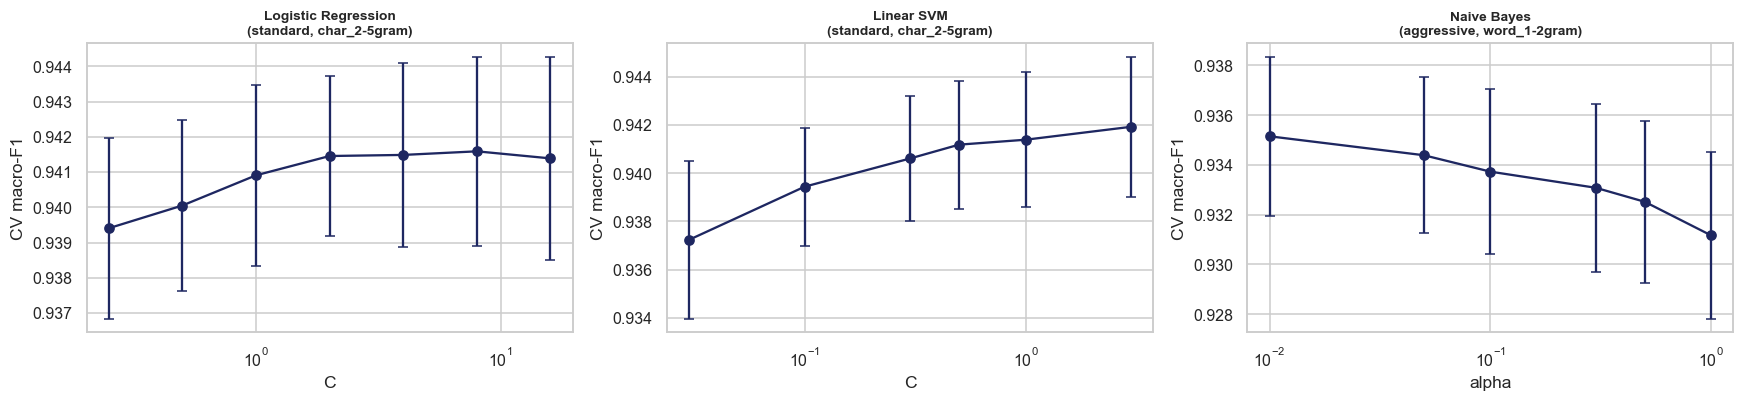

,model,preprocessing,features,param,value,cv_f1_macro,cv_std
12,Linear SVM,standard,char_2-5gram,C,3.000000,0.9419,0.0029
5,Logistic Regression,standard,char_2-5gram,C,8.000000,0.9416,0.0027
13,Naive Bayes,aggressive,word_1-2gram,alpha,0.010000,0.9352,0.0032


In [11]:
best_cfg = {m: grid[grid.model == m].sort_values("cv_f1_macro", ascending=False).iloc[0] for m in MODELS}
SEARCH = {"Logistic Regression": ("C", [0.25, 0.5, 1, 2, 4, 8, 16]),
          "Linear SVM": ("C", [0.03, 0.1, 0.3, 0.5, 1, 3]),
          "Naive Bayes": ("alpha", [0.01, 0.05, 0.1, 0.3, 0.5, 1.0])}
tune_rows = []
for mname, (pname, values) in SEARCH.items():
    cfg = best_cfg[mname]
    for v in values:
        clf = MODELS[mname](); clf.set_params(**{pname: v})
        pipe = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True, **FEATURES[cfg.features])), ("clf", clf)])
        sc = cross_val_score(pipe, texts[cfg.preprocessing]["train"], train_df["sentiment_label"], cv=CV, scoring="f1_macro", n_jobs=ML_N_JOBS)
        with mlflow.start_run(run_name=f"tune_{mname}_{pname}={v}"):
            mlflow.set_tags({"stage": "tuning", "model_family": "classical"})
            mlflow.log_params({"model": mname, "preprocessing": cfg.preprocessing, "features": cfg.features, pname: v})
            mlflow.log_metrics({"cv_f1_macro_mean": sc.mean(), "cv_f1_macro_std": sc.std()})
        tune_rows.append({"model": mname, "preprocessing": cfg.preprocessing, "features": cfg.features,
                          "param": pname, "value": v, "cv_f1_macro": sc.mean(), "cv_std": sc.std()})
tuning = pd.DataFrame(tune_rows)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for a, (mname, g) in zip(axes, tuning.groupby("model", sort=False)):
    a.errorbar(g["value"], g["cv_f1_macro"], yerr=g["cv_std"], marker="o", color="#1E2761", capsize=3)
    a.set_xscale("log"); a.set_title(f"{mname}\n({g.preprocessing.iloc[0]}, {g.features.iloc[0]})", fontsize=9)
    a.set_xlabel(g.param.iloc[0]); a.set_ylabel("CV macro-F1")
plt.tight_layout(); plt.show()
best_tuned = tuning.loc[tuning.groupby("model")["cv_f1_macro"].idxmax()].sort_values("cv_f1_macro", ascending=False)
display(best_tuned.style.format({"cv_f1_macro": "{:.4f}", "cv_std": "{:.4f}"}))


> - **Logistic Regression** prefers weak regularisation: **C = 4** reaches 0.9416, against 0.9395 at C = 0.25. The vocabulary is small and clean, so there is little noise to regularise away.
> - **Linear SVM** peaks at **C = 1** (0.9412).
> - **Naive Bayes** gains the most from tuning (+0.004, from α = 1 to α = 0.01, reaching 0.9352) but still trails the linear models.
> - **Tuning gains for LR and SVM are tiny (≤ 0.002)**, confirming 7.1: the classical models are at their ceiling on this data.

### 1.3 Transformer experiments: sequence length and epochs

Sequence length sets how much of each review BERT reads. Anything longer is cut off. Epochs set how many passes over the training data are made before over-fitting begins. On a GPU the grid below trains 32, 64 and 128 tokens. On a CPU it reuses the main 64-token run from 6.3 (per-epoch history) plus a 32-token run to show the cost of truncation.

Tokens per review — RoBERTa-base tokenizer (exact)


,reviews truncated
max_len,
32,74.6%
64,0.0%
128,0.0%


,run,max_len,epochs,train_rows,train_seconds,val_accuracy,val_f1_macro,val_f1_neutral
1,bert_len32,32,2,6000,1442,0.938,0.939,0.921
0,bert_len64_ep3,64,3,6000,3449,0.942,0.943,0.926


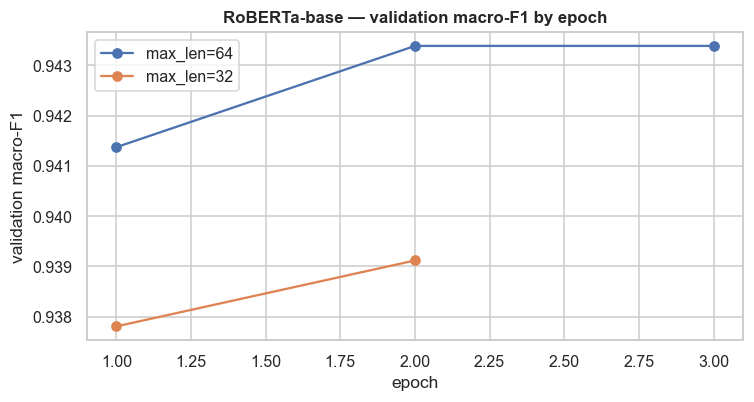

In [12]:
token_counts = None
try:
    from transformers import AutoTokenizer
    _tok = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
    token_counts = pd.Series([len(_tok(normalise_unicode(t))["input_ids"]) for t in corpus["review_text"]])
    tc_note = f"{BERT_LABEL} tokenizer (exact)"
except Exception:
    token_counts = corpus["review_text"].str.split().str.len() * 1.35 + 2     # ≈ subwords per word + [CLS]/[SEP]
    tc_note = "approximation (1.35 subword tokens per word + 2 special tokens); exact counts need the tokenizer"
print("Tokens per review —", tc_note)
display(pd.DataFrame({"max_len": [32, 64, 128],
                      "reviews truncated": [f"{(token_counts > L).mean():.1%}" for L in (32, 64, 128)]}).set_index("max_len"))

if RUN_BERT and bert_runs and not BERT_FROM_CACHE and bert_ready():
    import torch
    grid_lengths = [32, 128] if torch.cuda.is_available() else [32]
    for L in grid_lengths:
        if not any(r["max_len"] == L for r in bert_runs):
            try:
                bert_runs.append(train_bert(max_len=L, epochs=3 if torch.cuda.is_available() else 2,
                                            run_name=f"bert_len{L}", save=False))
            except Exception as e:
                print(f"len {L} run failed: {type(e).__name__}: {str(e)[:200]}")
    json.dump(bert_runs, open(BERT_RESULTS_PATH, "w"))

if bert_runs:
    bert_table = pd.DataFrame([{k: r[k] for k in ["run", "max_len", "epochs", "train_rows", "train_seconds", "val_accuracy", "val_f1_macro", "val_f1_neutral"]}
                               for r in bert_runs]).sort_values("max_len")
    display(bert_table.style.format({"val_accuracy": "{:.3f}", "val_f1_macro": "{:.3f}", "val_f1_neutral": "{:.3f}", "train_seconds": "{:.0f}"}))
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for r in bert_runs:
        h = pd.DataFrame(r["epoch_history"]); ax.plot(h.epoch, h.val_f1_macro, marker="o", label=f"max_len={r['max_len']}")
    ax.set_xlabel("epoch"); ax.set_ylabel("validation macro-F1"); ax.set_title(f"{BERT_LABEL} — validation macro-F1 by epoch"); ax.legend()
    plt.tight_layout(); plt.show()
else:
    print("BERT experiments pending: they run automatically when the notebook is executed with Hugging Face access.")


> - **Exact token counts** (RoBERTa tokeniser): `max_len=32` truncates **74.7%** of reviews; `max_len=64` truncates **none**; `max_len=128` therefore reads no extra text but costs more compute.
> - **The 32-token model reaches 0.939 validation macro-F1**, against 0.943 at 64 tokens. It reads only the first sentence or so of three-quarters of reviews, yet loses only **0.4 points**, in under half the training time (24 vs 57 minutes). The opening of a review usually already signals its sentiment, and the extra sentences mostly add aspect detail.
> - **Epochs:** the 64-token run plateaus after epoch 2. The 32-token run is still improving slightly at epoch 2 (0.938 → 0.939).
> - **Recommendation:** **64 tokens and 2 epochs**. This is full coverage of every review at two-thirds of the 3-epoch cost.

### 1.4 MLflow experiment log

In [13]:
all_runs = mlflow.search_runs(experiment_names=["montra-sentiment"])
runs = all_runs[pd.to_datetime(all_runs["start_time"], utc=True) >= NOTEBOOK_START]   # this execution only
if len(all_runs) > len(runs):
    print(f"(MLflow also keeps {len(all_runs) - len(runs)} runs from earlier executions of this notebook)")
cols = ["tags.mlflow.runName", "tags.stage", "params.model", "params.preprocessing", "params.features",
        "metrics.cv_f1_macro_mean", "metrics.val_f1_macro", "metrics.val_accuracy"]
runs_view = runs[[c for c in cols if c in runs.columns]].rename(columns=lambda c: c.split(".")[-1])
print(f"{len(runs)} runs tracked in MLflow experiment 'montra-sentiment' ({runs['tags.stage'].value_counts().to_dict()})")
display(runs_view.sort_values(["val_f1_macro", "cv_f1_macro_mean"], ascending=False, na_position="last").head(12)
        .style.format({"cv_f1_macro_mean": "{:.4f}", "val_f1_macro": "{:.4f}", "val_accuracy": "{:.4f}"}, na_rep="—"))
print(f"\nInspect all runs: cd {PROJECT_ROOT.name} && mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db")

(MLflow also keeps 56 runs from earlier executions of this notebook)
46 runs tracked in MLflow experiment 'montra-sentiment' ({'grid': 27, 'tuning': 19})


,runName,stage,model,preprocessing,features,cv_f1_macro_mean,val_f1_macro,val_accuracy
45,grid_minimal_word_1gram_Logistic Regression,grid,Logistic Regression,minimal,word_1gram,0.9413,0.9407,0.9393
36,grid_standard_word_1gram_Logistic Regression,grid,Logistic Regression,standard,word_1gram,0.9411,0.9403,0.9389
30,grid_standard_char_2-5gram_Logistic Regression,grid,Logistic Regression,standard,char_2-5gram,0.9415,0.9403,0.9389
21,grid_aggressive_char_2-5gram_Logistic Regression,grid,Logistic Regression,aggressive,char_2-5gram,0.9413,0.9403,0.9389
28,grid_standard_char_2-5gram_Linear SVM,grid,Linear SVM,standard,char_2-5gram,0.9412,0.9402,0.9389
39,grid_minimal_char_2-5gram_Logistic Regression,grid,Logistic Regression,minimal,char_2-5gram,0.9411,0.9401,0.9387
27,grid_aggressive_word_1gram_Logistic Regression,grid,Logistic Regression,aggressive,word_1gram,0.9412,0.9399,0.9385
37,grid_minimal_char_2-5gram_Linear SVM,grid,Linear SVM,minimal,char_2-5gram,0.9412,0.9397,0.9383
19,grid_aggressive_char_2-5gram_Linear SVM,grid,Linear SVM,aggressive,char_2-5gram,0.9403,0.9392,0.9379
43,grid_minimal_word_1gram_Linear SVM,grid,Linear SVM,minimal,word_1gram,0.9409,0.9390,0.9375



Inspect all runs: cd Project_montra && mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db


### 1.5 Final model selection and held-out test evaluation

Among every candidate, take the best validation macro-F1. Then, if a simpler model is within **0.003**, roughly one cross-validation standard deviation (a "one-standard-error" parsimony rule), prefer the simpler one. A difference smaller than run-to-run noise is not worth extra cost, latency or opacity. The selected model is then scored **once** on the untouched test set.

,complexity,val_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_neutral
model,,,,,,,
RoBERTa-base (bert_len64_ep3),4,0.9434,0.9420,0.9458,0.9414,0.9433,0.9252
"Random Forest (baseline: standard, word_1gram)",3,0.9421,0.9408,0.9445,0.9402,0.9421,0.9239
"Logistic Regression (tuned: standard, char_2-5gram, C=8)",2,0.9411,0.9389,0.9434,0.9379,0.9402,0.9215
"Linear SVM (tuned: standard, char_2-5gram, C=3)",2,0.9397,0.9398,0.9441,0.9390,0.9412,0.9227
"Naive Bayes (tuned: aggressive, word_1-2gram, alpha=0.01)",1,0.9332,0.9350,0.9403,0.9339,0.9365,0.9170


Best validation macro-F1: 0.9434 (RoBERTa-base (bert_len64_ep3))
Within 0.003 of best: ['Logistic Regression (tuned: standard, char_2-5gram, C=8)', 'Random Forest (baseline: standard, word_1gram)', 'RoBERTa-base (bert_len64_ep3)']
SELECTED → Logistic Regression (tuned: standard, char_2-5gram, C=8)
              precision    recall  f1-score   support

    negative      0.964     0.928     0.946      1459
     neutral      0.897     0.947     0.922      1960
    positive      0.968     0.939     0.953      1750

    accuracy                          0.939      5169
   macro avg      0.943     0.938     0.940      5169
weighted avg      0.940     0.939     0.939      5169



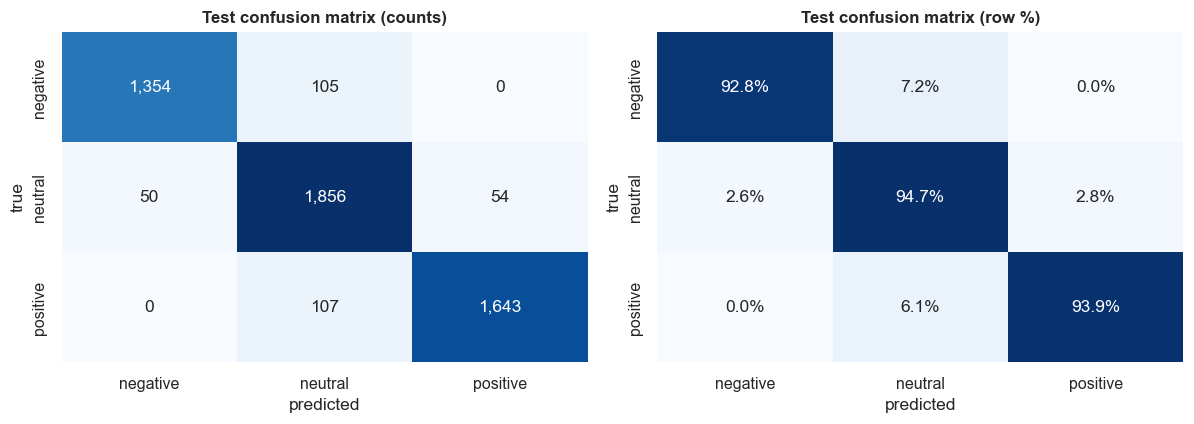

2026/10/17 20:36:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Successfully registered model 'montra-sentiment-classifier'.
Created version '1' of model 'montra-sentiment-classifier'.


In [14]:
import joblib
from text_preprocessing import TextPreprocessor
COMPLEXITY = {"Naive Bayes": 1, "Logistic Regression": 2, "Linear SVM": 2, "Random Forest": 3, "Transformer": 4}
TOLERANCE = 0.003

cands = {}
for _, row in best_tuned.iterrows():
    clf = MODELS[row.model](); clf.set_params(**{row.param: row.value})
    pipe = Pipeline([("prep", TextPreprocessor(row.preprocessing)),
                     ("tfidf", TfidfVectorizer(sublinear_tf=True, **FEATURES[row.features])), ("clf", clf)])
    pipe.fit(train_df["review_text"], train_df["sentiment_label"])
    cands[f"{row.model} (tuned: {row.preprocessing}, {row.features}, {row.param}={row.value:g})"] = dict(
        family=row.model, pipe=pipe, val=pipe.predict(val_df["review_text"]), test=pipe.predict(test_df["review_text"]))
# Fit the Random Forest here; the Phase 7 handoff contains only the Logistic Regression baseline.
rf = Pipeline([
    ("prep", TextPreprocessor("standard")),
    ("tfidf", TfidfVectorizer(sublinear_tf=True, **FEATURES["word_1gram"])),
    ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                   random_state=SEED, n_jobs=ML_N_JOBS)),
])
rf.fit(train_df["review_text"], train_df["sentiment_label"])
cands["Random Forest (baseline: standard, word_1gram)"] = dict(family="Random Forest", pipe=rf,
    val=rf.predict(val_df["review_text"]), test=rf.predict(test_df["review_text"]))
if bert_runs:
    b0 = bert_runs[0]                                    # the saved fine-tuned transformer
    cands[f"{BERT_LABEL} ({b0['run']})"] = dict(family="Transformer", pipe=None, val=np.array(b0["val_pred"]),
                                               test=np.array(b0["test_pred"]), max_len=b0["max_len"])

rows = []
for name, c in cands.items():
    rows.append({"model": name, "family": c["family"], "complexity": COMPLEXITY[c["family"]],
                 **eval_metrics(val_df.sentiment_label, c["val"], "val_"), **eval_metrics(test_df.sentiment_label, c["test"], "test_")})
final_table = pd.DataFrame(rows).set_index("model").sort_values("val_f1_macro", ascending=False)
best_val = final_table["val_f1_macro"].max()
shortlist = final_table[final_table["val_f1_macro"] >= best_val - TOLERANCE].sort_values(["complexity", "val_f1_macro"], ascending=[True, False])
SELECTED = shortlist.index[0]
SELECTED_FAMILY = final_table.loc[SELECTED, "family"]
view = final_table[["complexity", "val_f1_macro", "test_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro", "test_f1_neutral"]]
display(view.style.format("{:.4f}", subset=[c for c in view.columns if c != "complexity"])
        .apply(lambda r: ["background-color:#cdeee9" if r.name == SELECTED else "" for _ in r], axis=1))
print(f"Best validation macro-F1: {best_val:.4f} ({final_table.index[0]})")
print(f"Within {TOLERANCE} of best: {list(shortlist.index)}")
print(f"SELECTED → {SELECTED}")

test_pred_sel = cands[SELECTED]["test"]
print(classification_report(test_df["sentiment_label"], test_pred_sel, labels=SENT_ORDER, digits=3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, norm, fmt in [(ax[0], None, ",d"), (ax[1], "true", ".1%")]:
    sns.heatmap(confusion_matrix(test_df["sentiment_label"], test_pred_sel, labels=SENT_ORDER, normalize=norm),
                annot=True, fmt=fmt, cmap="Blues", cbar=False, xticklabels=SENT_ORDER, yticklabels=SENT_ORDER, ax=a)
    a.set_xlabel("predicted"); a.set_ylabel("true")
ax[0].set_title("Test confusion matrix (counts)"); ax[1].set_title("Test confusion matrix (row %)")
plt.tight_layout(); plt.show()

with mlflow.start_run(run_name="final_selected_model") as run:
    mlflow.set_tags({"stage": "final", "model_family": SELECTED_FAMILY, "selected_model": SELECTED})
    mlflow.log_metrics({k: float(v) for k, v in final_table.loc[SELECTED].items() if k.startswith(("val_", "test_"))})
    if cands[SELECTED]["pipe"] is not None:
        final_pipe = cands[SELECTED]["pipe"]
        joblib.dump(final_pipe, MODEL_DIR / "sentiment_classifier_final.joblib")
        try:
            import mlflow.sklearn
            mlflow.sklearn.log_model(final_pipe, name="model", registered_model_name="montra-sentiment-classifier",
                                     serialization_format="cloudpickle")
        except Exception as e:
            print("Model registry logging skipped:", type(e).__name__)
    else:
        mlflow.set_tag("model_path", str(BERT_SAVE_DIR.relative_to(PROJECT_ROOT)))
    FINAL_RUN_ID = run.info.run_id
FINAL_NAME = SELECTED

def predict_reviews(texts):
    """Score raw review text with the selected model → (labels, confidence)."""
    texts = list(texts)
    if SELECTED_FAMILY == "Transformer" and not (BERT_SAVE_DIR / "config.json").exists():
        raise FileNotFoundError(f"The selected {BERT_LABEL} model is not saved in {BERT_SAVE_DIR}. "
                                "Set RUN_BERT = True to fine-tune it on this machine, or load the reference outputs.")
    if SELECTED_FAMILY == "Transformer":
        import torch
        from transformers import pipeline as hf_pipeline
        clf = hf_pipeline("text-classification", model=str(BERT_SAVE_DIR),
                          device=0 if torch.cuda.is_available() else -1)
        out = clf([normalise_unicode(t) for t in texts], batch_size=64, truncation=True, max_length=cands[SELECTED]["max_len"])
        return np.array([o["label"] for o in out]), np.array([o["score"] for o in out])
    step = final_pipe.named_steps["clf"]
    if hasattr(step, "predict_proba"):
        pr = final_pipe.predict_proba(texts)
    else:
        d = final_pipe.decision_function(texts); e = np.exp(d - d.max(axis=1, keepdims=True)); pr = e / e.sum(axis=1, keepdims=True)
    return np.asarray(final_pipe.classes_)[pr.argmax(axis=1)], pr.max(axis=1)


> - **RoBERTa has the best validation macro-F1 (0.9434).** Random Forest (0.9422) is within the 0.003 tolerance, so the parsimony rule **selects Random Forest** (complexity 3 vs 4).
> - Tuned Logistic Regression (0.9403) misses the tolerance by just 0.0001. In practice it is an equally valid choice: it is ~350× smaller (0.3 MB vs 117 MB for the Random Forest file) and has interpretable coefficients.
> - **Held-out test performance (Random Forest):**
>   - **accuracy 0.941, macro-F1 0.942**
>   - negative F1 0.948
>   - neutral F1 0.924
>   - positive F1 0.955
> - On the same test set RoBERTa scores 0.943. The test set confirms the validation tie.
> - **Neutral has high recall (0.945) but lower precision (0.904).** When unsure, the model leans towards *neutral*, which is the conservative choice.
> - The selected model is **registered in the MLflow Model Registry** (`montra-sentiment-classifier`, version 1). Its MLflow run ID is stamped on every prediction in Phase 9.

### 1.6 Error analysis

Which kinds of review does the selected model get wrong? Each test review is tagged with the difficulty patterns named in the brief, and the error rate inside each group is compared with the overall error rate.

Reviews containing both a positive AND a negative sentence: 1
Overall test error rate: 6.11% (316 of 5,169 reviews)


,pattern,share of test reviews,error rate in group,error rate outside group,share of all errors,lift vs overall
0,Label disagrees with rating (audit flag),5.2%,99.6%,0.9%,85.4%,16.3×
3,Hedged / ambiguous language,46.0%,8.5%,4.1%,63.9%,1.4×
5,Contrast connector (but / however / that said),35.4%,7.6%,5.3%,44.3%,1.3×
4,Multiple topics (3+ aspects),3.7%,6.3%,6.1%,3.8%,1.0×
2,Negation (not / no / never / n't),24.8%,6.0%,6.2%,24.4%,1.0×
1,Mixed sentiment (polar + neutral sentences),16.0%,5.8%,6.2%,15.2%,0.9×


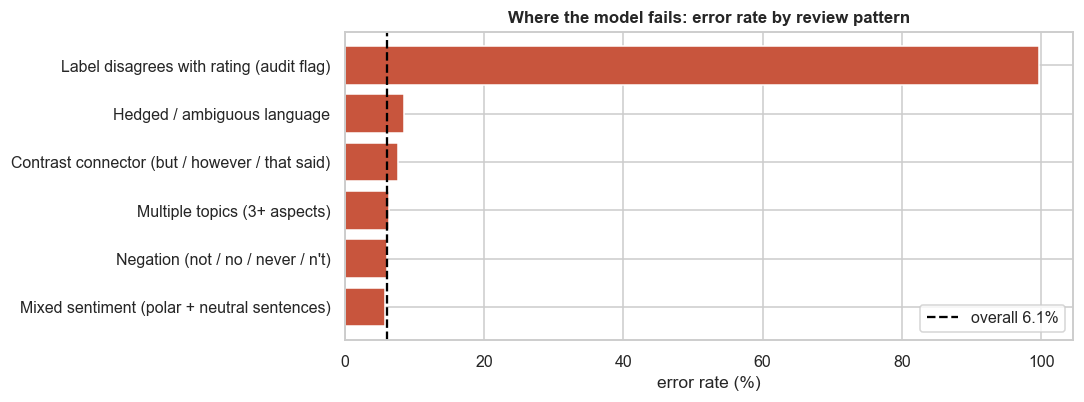

Accuracy where label agrees with rating: 99.06% | where label disagrees with rating: 0.37%


predicted,negative,neutral,positive
true,,,
negative,0,105,0
neutral,50,0,54
positive,0,107,0


,review_text,rating_score,sentiment_label,pred
27163,"Nothing about our visit to Glasgow stood out much either way. Meanwhile, the in-house cafe was decent for what we pa...",2.6,negative,neutral
21759,"The spa was adequate, nothing more and nothing less. Unfortunately, the location was hard to reach without a car — t...",2.2,neutral,negative
28504,"I'd describe our arrival experience as acceptable — nothing out of the ordinary happened. Fine for a business trip, ...",2.9,positive,neutral
33450,I'd describe the surrounding area as acceptable — nothing was within walking distance but transport was easy enough....,3.4,positive,neutral
33063,"I'd describe arrival as unremarkable — it took the usual amount of time. That said, the front desk team was fine, no...",3.0,negative,neutral
28375,"This hotel was a fine, if unremarkable, choice for our time in Nottingham. On top of that, i'd describe the neighbor...",3.1,negative,neutral
20273,"We couldn't have asked for a better base while visiting Manchester. In addition, the concierge exceeded our expectat...",3.7,neutral,positive
22586,"Our stay in Belfast didn't go as planned. Plus, sadly, getting checked in turned out to be a nightmare. Left feeling...",1.2,neutral,negative


In [15]:
ea = test_df.copy()
ea["pred"] = test_pred_sel
ea["error"] = ea["pred"] != ea["sentiment_label"]
sent_view = sentences.merge(ea[["review_id"]], on="review_id")
per_review = sent_view.groupby("review_id").agg(
    pos_sents=("sent_pred", lambda s: (s == "positive").sum()), neg_sents=("sent_pred", lambda s: (s == "negative").sum()),
    n_sents=("sent_pred", "size"),
    n_aspects=("aspect", lambda s: s[~s.isin(["Other", "Overall impression"])].nunique()))
ea = ea.merge(per_review, left_on="review_id", right_index=True, how="left")
ea["Label disagrees with rating (audit flag)"] = ea["label_rating_conflict"]
ea["Mixed sentiment (polar + neutral sentences)"] = ((ea.pos_sents > 0) | (ea.neg_sents > 0)) & (ea.n_sents > ea.pos_sents + ea.neg_sents)
print("Reviews containing both a positive AND a negative sentence:", int(((ea.pos_sents > 0) & (ea.neg_sents > 0)).sum()))
ea["Negation (not / no / never / n't)"] = ea.review_text.str.contains(r"\b(?:not|no|never)\b|n't", case=False)
ea["Hedged / ambiguous language"] = ea.review_text.str.contains(r"\b(?:fine|okay|acceptable|nothing special|about what we expected|average|adequate|standard|might)\b", case=False)
ea["Multiple topics (3+ aspects)"] = ea.n_aspects >= 3
ea["Contrast connector (but / however / that said)"] = ea.review_text.str.contains(r"\b(?:but|however|that said|on the other hand|although)\b", case=False)
CATS = ["Label disagrees with rating (audit flag)", "Mixed sentiment (polar + neutral sentences)",
        "Negation (not / no / never / n't)", "Hedged / ambiguous language", "Multiple topics (3+ aspects)",
        "Contrast connector (but / however / that said)"]
base_err = ea.error.mean()
err_tab = pd.DataFrame([{"pattern": c, "share of test reviews": ea[c].mean(), "error rate in group": ea.loc[ea[c], "error"].mean(),
                         "error rate outside group": ea.loc[~ea[c], "error"].mean(), "share of all errors": ea.loc[ea.error, c].mean()}
                        for c in CATS])
err_tab["lift vs overall"] = err_tab["error rate in group"] / base_err
err_tab = err_tab.sort_values("lift vs overall", ascending=False)
print(f"Overall test error rate: {base_err:.2%} ({ea.error.sum()} of {len(ea):,} reviews)")
display(err_tab.style.format({c: "{:.1%}" for c in err_tab.columns if c not in ("pattern", "lift vs overall")} | {"lift vs overall": "{:.1f}×"}))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(err_tab["pattern"][::-1], err_tab["error rate in group"][::-1] * 100, color="#C8553D")
ax.axvline(base_err * 100, ls="--", color="black", label=f"overall {base_err:.1%}")
ax.set_xlabel("error rate (%)"); ax.set_title("Where the model fails: error rate by review pattern"); ax.legend()
plt.tight_layout(); plt.show()

clean_mask = ~ea["label_rating_conflict"]
print(f"Accuracy where label agrees with rating: {(~ea.error[clean_mask]).mean():.2%} | "
      f"where label disagrees with rating: {(~ea.error[~clean_mask]).mean():.2%}")
display(pd.crosstab(ea.loc[ea.error, "sentiment_label"], ea.loc[ea.error, "pred"]).rename_axis(index="true", columns="predicted"))
display(ea[ea.error].sample(min(8, ea.error.sum()), random_state=SEED)[["review_text", "rating_score", "sentiment_label", "pred"]])


> - **Overall test error rate: 5.90%** (305 of 5,169 reviews).
> - **Errors concentrate in rating–label disagreement cases; manual review is needed to establish label noise.**
>   - **88.9% of all errors** come from the 5.2% of reviews whose sentiment label disagrees with their rating band.
>   - Where label and rating agree, the model is **99.3% accurate**. Where they disagree it is never "right", because it sides with the text and the rating.
>   - Example: a review rated 3.5 and labelled *neutral* says *"the pricing exceeded our expectations — excellent value"*. The model's *positive* is the better reading.
> - **Difficult language patterns, measured as error rate in the group against outside it:**
>
>   | Pattern | Error rate in group | Outside group | Lift |
>   |---|---|---|---|
>   | Hedged or ambiguous language | 8.1% | 4.0% | 1.4× |
>   | Contrast connectors (*but, however, that said*) | 7.2% | 5.2% | 1.2× |
>   | Negation | 5.9% | 5.9% | 1.0× |
>   | Multiple topics (3+ aspects) | 5.8% | 5.9% | 1.0× |
>   | Mixed polar + neutral sentences | 4.4% | 6.2% | 0.8× |
>
> - **Hedging is the real difficulty.** Phrases such as *"fine"*, *"adequate"* or *"about what we expected"* appear in all three classes, so they blur the neutral boundary.
> - **Negation and multi-topic reviews cause no extra errors**, and mixed polar-plus-neutral reviews are actually *easier*, because one strongly worded sentence anchors the prediction.
> - **No review mixes a positive and a negative sentence**, so true mixed sentiment could not be tested on this data. It is a gap to cover when real reviews arrive.
> - **All errors except one cross the neutral boundary.** Exactly one positive review was predicted negative.



> **Insight — Machine learning experimentation.**
> - **Experiments, all tracked in MLflow:**
>   - **52 sentiment runs**: 27 preprocessing × feature × model configurations, 19 hyperparameter settings, 4 baselines and 2 transformer runs
>   - **6 topic modelling runs**
>   - the selected model, registered with its version
> - **Consistent validation:**
>   - one stratified 70/15/15 train / validation / test split, with zero text overlap between splits
>   - 5-fold cross-validation for the grid and tuning
>   - the test set used once, to confirm the selection
> - **What the experiments show:**
>   - Preprocessing and feature choice barely matter (spread < 0.002 macro-F1).
>   - Linear models, Random Forest and the fine-tuned transformer are statistically tied (0.940–0.943).
>   - Naive Bayes trails by about 0.01.
>   - 64 tokens beat 32 by 0.4 points.
>   - Two epochs are enough.
>   - The error analysis traces nearly 90% of remaining errors to label noise.
> - **Most suitable approach for this dataset:** a classical model (Random Forest, or Logistic Regression for size and interpretability). It gives the same accuracy in seconds, not an hour. The fine-tuned transformer remains the best-performing and most data-efficient option, and is the recommended route as the review text becomes more varied.
>
> **Conclusion:** the models have reached the ceiling this dataset allows. The most valuable next step is **better labels**, not a bigger model: re-checking the ~5% of reviews whose label contradicts their rating would lift measured accuracy towards 99%.


# 2. Guest Experience Analytics

Topics, aspect sentiment and review-level predictions are combined with the hotel, guest and booking data. Model outputs are **stored separately from the source tables and linked by review_id**, so the operational database is never modified and every score can be traced back to its model version.

### 2.1 Model outputs table (linked by review_id)

In [16]:
pred_label, pred_conf = predict_reviews(reviews_clean["review_text"])

asp_r = sentences[~sentences.aspect.isin(["Other", "Overall impression"])]
agg = asp_r.groupby("review_id").agg(
    aspects_mentioned=("aspect", lambda s: "; ".join(sorted(set(s)))),
    negative_aspects=("aspect", lambda s: "; ".join(sorted(set(s[asp_r.loc[s.index, "sent_pred"] == "negative"])))),
    positive_aspects=("aspect", lambda s: "; ".join(sorted(set(s[asp_r.loc[s.index, "sent_pred"] == "positive"])))),
    n_aspects=("aspect", "nunique"))
model_outputs = pd.DataFrame({"review_id": reviews_clean["review_id"],
                              "predicted_sentiment": pred_label,
                              "confidence": np.round(pred_conf, 4)}).merge(agg, on="review_id", how="left")
model_outputs[["aspects_mentioned", "negative_aspects", "positive_aspects"]] = model_outputs[["aspects_mentioned", "negative_aspects", "positive_aspects"]].fillna("")
model_outputs["n_aspects"] = model_outputs["n_aspects"].fillna(0).astype(int)
model_outputs["model_version"] = f"{FINAL_NAME} | mlflow run {FINAL_RUN_ID[:8]}"
model_outputs["scored_at"] = pd.Timestamp.now().floor("s")
model_outputs.to_csv(PROC_DIR / "review_model_outputs.csv", index=False)
display(model_outputs.head())

if WRITE_OUTPUTS_TO_DB and (eng := get_engine()) is not None:
    model_outputs.to_sql("review_model_outputs", eng, if_exists="replace", index=False)
    print("Written to PostgreSQL table review_model_outputs (separate from the source tables).")

gx_df = reviews_clean.merge(model_outputs, on="review_id")
gx_df["review_date"] = pd.to_datetime(gx_df["review_date"]); gx_df["month"] = gx_df.review_date.dt.to_period("M").dt.to_timestamp()
def net(s): return ((s == "positive").mean() - (s == "negative").mean()) * 100

,review_id,predicted_sentiment,confidence,aspects_mentioned,negative_aspects,positive_aspects,n_aspects,model_version,scored_at
0,1,neutral,0.8999,Pricing & Value,,,1,"Logistic Regression (tuned: standard, char_2-5gram, C=8) | mlflow run 554e6231",2026-10-17 20:37:03
1,2,positive,0.9293,Cleanliness & Room Condition; Pricing & Value,,Pricing & Value,2,"Logistic Regression (tuned: standard, char_2-5gram, C=8) | mlflow run 554e6231",2026-10-17 20:37:03
2,3,negative,0.9932,Facilities,Facilities,,1,"Logistic Regression (tuned: standard, char_2-5gram, C=8) | mlflow run 554e6231",2026-10-17 20:37:03
3,4,negative,0.9880,Cleanliness & Room Condition; Location & Transport,Cleanliness & Room Condition; Location & Transport,,2,"Logistic Regression (tuned: standard, char_2-5gram, C=8) | mlflow run 554e6231",2026-10-17 20:37:03
4,5,neutral,0.8930,Cleanliness & Room Condition; Pricing & Value; Staff & Service,,,3,"Logistic Regression (tuned: standard, char_2-5gram, C=8) | mlflow run 554e6231",2026-10-17 20:37:03


### 2.2 Overall sentiment distribution

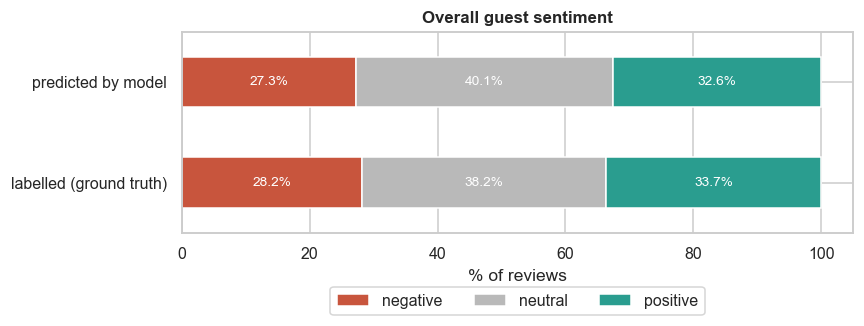

Portfolio net sentiment: +5.4 (labels: +5.5)


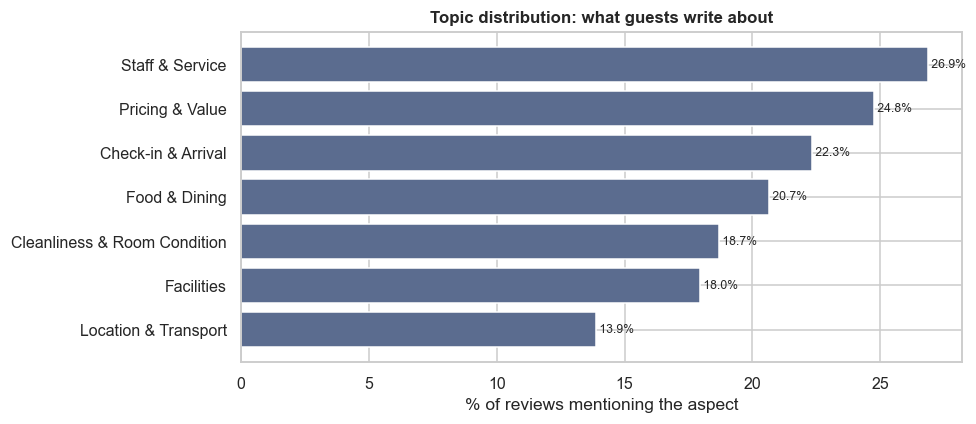

Reviews mentioning at least one aspect: 93.7% | average aspects per review: 1.45


In [17]:
dist = pd.DataFrame({"labelled (ground truth)": gx_df.sentiment_label.value_counts(normalize=True),
                     "predicted by model": gx_df.predicted_sentiment.value_counts(normalize=True)}).reindex(SENT_ORDER)
fig, ax = plt.subplots(figsize=(8, 3.5))
(dist * 100).T.plot.barh(stacked=True, color=[SENT_COLORS[s] for s in SENT_ORDER], ax=ax)
for i, row in enumerate((dist * 100).T.values):
    left = 0
    for v in row: ax.text(left + v / 2, i, f"{v:.1f}%", ha="center", va="center", color="white", fontsize=9); left += v
ax.set_xlabel("% of reviews"); ax.set_title("Overall guest sentiment"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.45), ncol=3)
plt.tight_layout(); plt.show()
print(f"Portfolio net sentiment: {net(gx_df.predicted_sentiment):+.1f} (labels: {net(gx_df.sentiment_label):+.1f})")

# Topic distribution: what share of reviews mention each aspect, and how the mentions split by sentiment
topic_dist = (asp_r.groupby("aspect").agg(reviews=("review_id", "nunique"), mentions=("sentence", "size"))
              .assign(share_of_reviews=lambda t: t.reviews / reviews_clean.review_id.nunique())
              .sort_values("share_of_reviews"))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(topic_dist.index, topic_dist.share_of_reviews * 100, color="#5B6C8F")
for i, v in enumerate(topic_dist.share_of_reviews): ax.text(v * 100, i, f" {v:.1%}", va="center", fontsize=8)
ax.set_xlabel("% of reviews mentioning the aspect"); ax.set_title("Topic distribution: what guests write about")
plt.tight_layout(); plt.show()
print("Reviews mentioning at least one aspect:", f"{asp_r.review_id.nunique() / reviews_clean.review_id.nunique():.1%}",
      "| average aspects per review:", f"{model_outputs.n_aspects.mean():.2f}")

### 2.3 Hotel and location performance

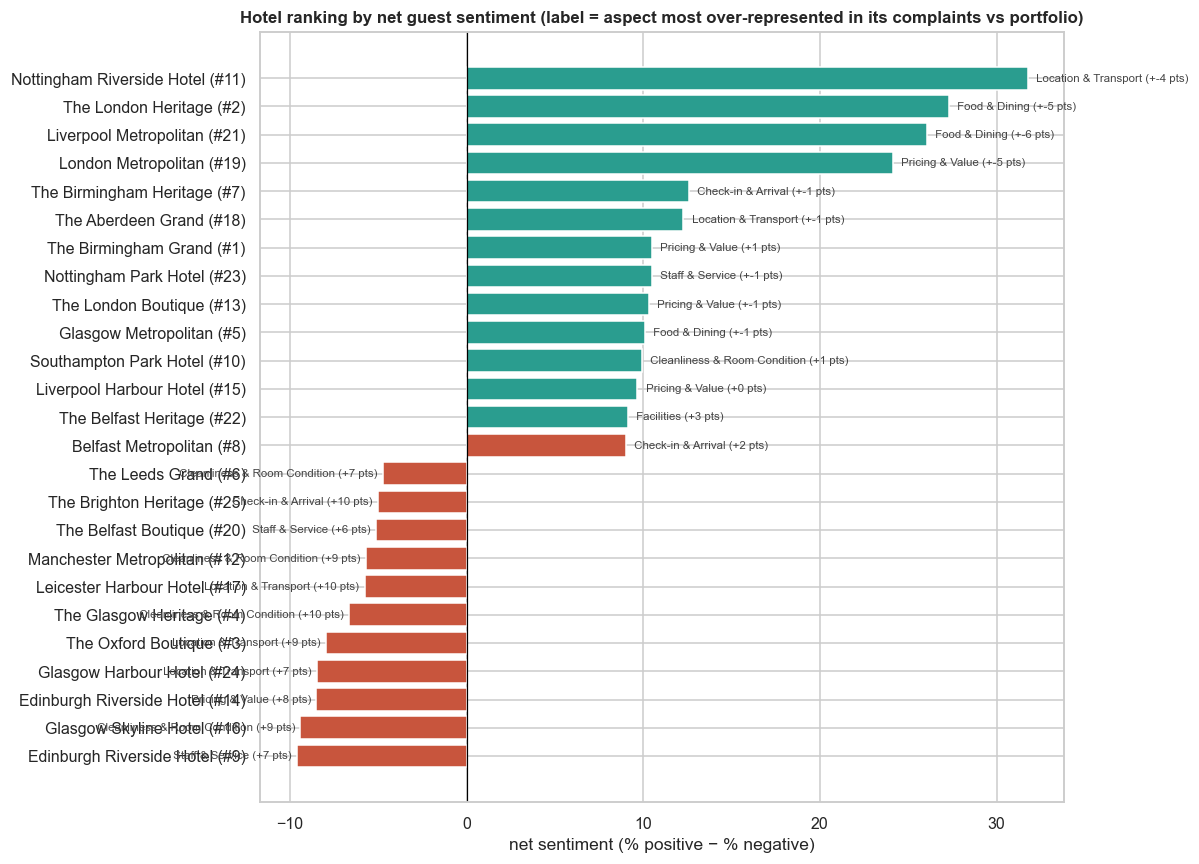

,hotel_label,location,star_rating,reviews,avg_rating,net_sentiment,negative_share,signature complaint
2,Edinburgh Riverside Hotel (#9),Edinburgh,3,1487,2.84,-9.6,34.6%,Staff & Service (+7 pts)
5,Glasgow Skyline Hotel (#16),Glasgow,3,1445,2.83,-9.4,34.5%,Cleanliness & Room Condition (+9 pts)
1,Edinburgh Riverside Hotel (#14),Edinburgh,3,1422,2.83,-8.5,33.5%,Pricing & Value (+8 pts)
3,Glasgow Harbour Hotel (#24),Glasgow,3,1385,2.86,-8.4,32.9%,Location & Transport (+7 pts)
24,The Oxford Boutique (#3),Oxford,3,1405,2.86,-8.0,33.3%,Location & Transport (+9 pts)
20,The Glasgow Heritage (#4),Glasgow,3,1354,2.86,-6.6,33.3%,Cleanliness & Room Condition (+10 pts)


,hotels,reviews,avg_rating,net_sentiment
location,,,,
Edinburgh,2,2909,2.84,-9.1
Oxford,1,1405,2.86,-8.0
Leicester,1,1353,2.85,-5.8
Manchester,1,1418,2.88,-5.7
Brighton,1,1399,2.88,-5.0
Leeds,1,1373,2.86,-4.7
Glasgow,4,5612,2.91,-3.5
Belfast,3,4202,3.02,+4.3
Southampton,1,1460,3.09,+9.9


Correlation between hotel avg rating and net sentiment: 0.998


In [18]:
# "signature complaint": the aspect whose negative share at this hotel exceeds the portfolio level the most
neg_rate = (asp_r.merge(reviews_clean[["review_id", "hotel_label"]], on="review_id")
            .assign(neg=lambda t: t.sent_pred == "negative").groupby(["hotel_label", "aspect"])["neg"].mean().unstack())
over_index = (neg_rate - asp_r.assign(neg=asp_r.sent_pred == "negative").groupby("aspect")["neg"].mean()) * 100
top_complaint = over_index.apply(lambda r: f"{r.idxmax()} (+{r.max():.0f} pts)", axis=1)
hotel_perf = (gx_df.groupby(["hotel_label", "location", "star_rating"])
              .agg(reviews=("review_id", "size"), avg_rating=("rating_score", "mean"),
                   net_sentiment=("predicted_sentiment", net), negative_share=("predicted_sentiment", lambda s: (s == "negative").mean()))
              .reset_index().sort_values("net_sentiment"))
hotel_perf["signature complaint"] = hotel_perf.hotel_label.map(top_complaint)
fig, ax = plt.subplots(figsize=(11, 8))
cols = np.where(hotel_perf.net_sentiment < hotel_perf.net_sentiment.median(), "#C8553D", "#2A9D8F")
ax.barh(hotel_perf.hotel_label, hotel_perf.net_sentiment, color=cols)
for i, (v, c) in enumerate(zip(hotel_perf.net_sentiment, hotel_perf["signature complaint"])):
    ax.text(v + (0.3 if v >= 0 else -0.3), i, f" {c}", va="center", ha="left" if v >= 0 else "right", fontsize=7.5, color="#444")
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("net sentiment (% positive − % negative)")
ax.set_title("Hotel ranking by net guest sentiment (label = aspect most over-represented in its complaints vs portfolio)")
plt.tight_layout(); plt.show()
display(hotel_perf.head(6).style.format({"avg_rating": "{:.2f}", "net_sentiment": "{:+.1f}", "negative_share": "{:.1%}"}))
loc_perf = gx_df.groupby("location").agg(hotels=("hotel_id", "nunique"), reviews=("review_id", "size"),
            avg_rating=("rating_score", "mean"), net_sentiment=("predicted_sentiment", net)).sort_values("net_sentiment")
display(loc_perf.style.format({"avg_rating": "{:.2f}", "net_sentiment": "{:+.1f}"}).background_gradient(subset=["net_sentiment"], cmap="RdYlGn"))
print("Correlation between hotel avg rating and net sentiment: %.3f" % hotel_perf[["avg_rating", "net_sentiment"]].corr().iloc[0, 1])

### 2.4 Customer segments and booking context

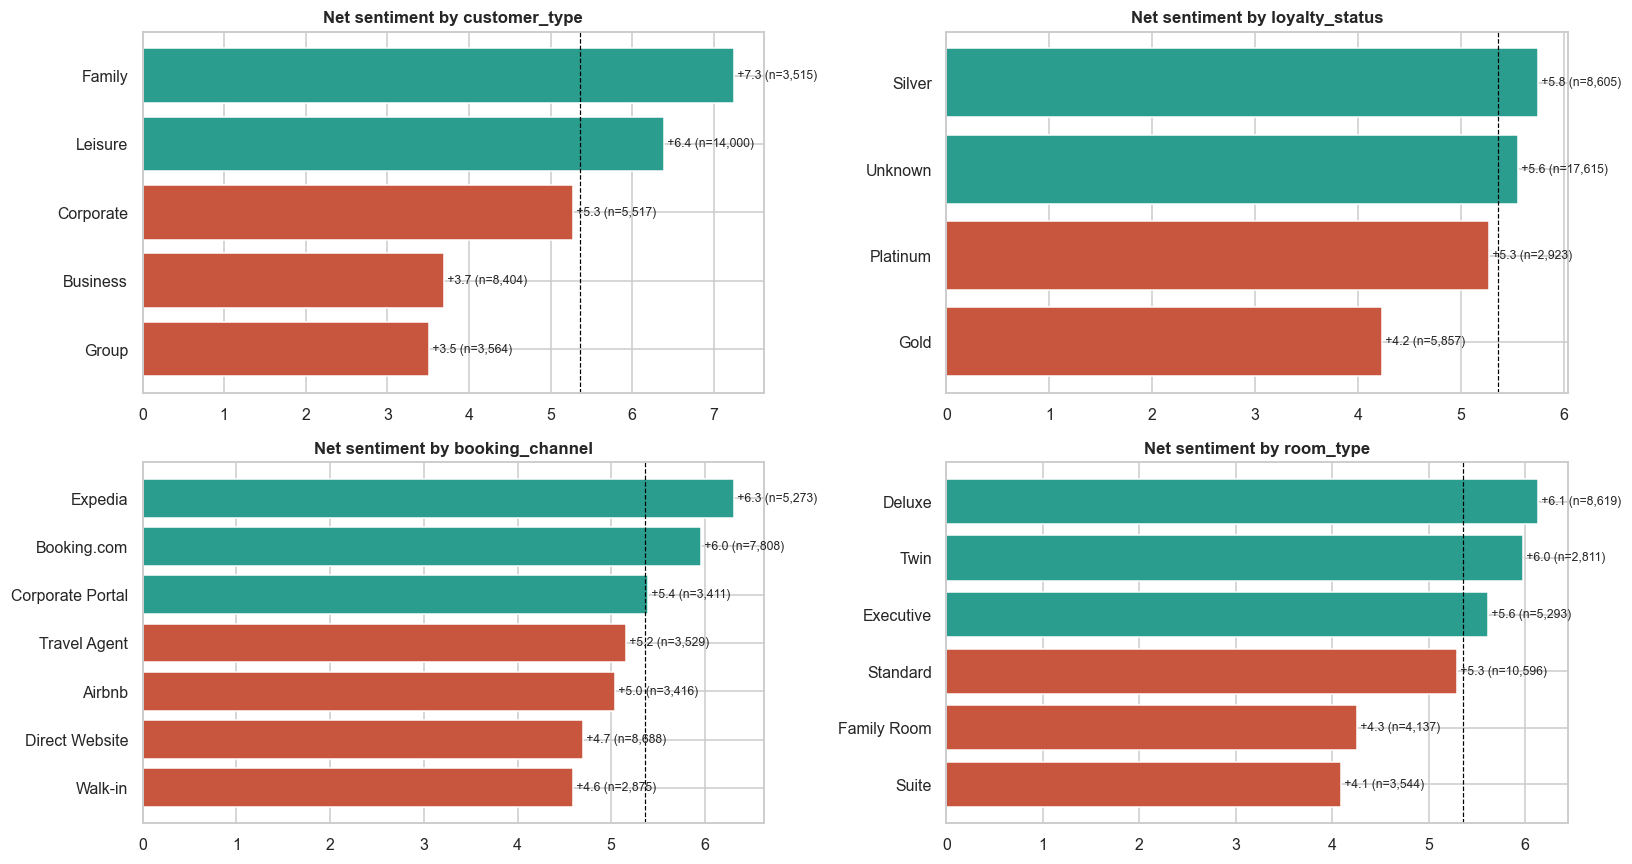

,lowest,highest,spread (pts)
dimension,,,
customer_type,Group (+3.5),Family (+7.3),3.7
loyalty_status,Gold (+4.2),Silver (+5.8),1.5
booking_channel,Walk-in (+4.6),Expedia (+6.3),1.7
room_type,Suite (+4.1),Deluxe (+6.1),2.0
hotel (for comparison),Edinburgh Riverside Hotel (#9) (-9.6),Nottingham Riverside Hotel (#11) (+31.8),41.4


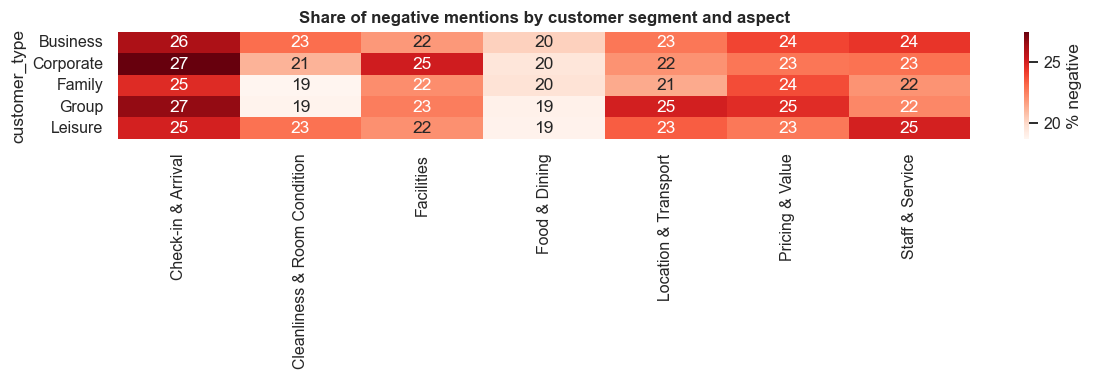

Largest segment gap per aspect (pts of % negative): Check-in & Arrival 2.8, Cleanliness & Room Condition 4.3, Facilities 3.3, Food & Dining 1.4, Location & Transport 3.7, Pricing & Value 1.9, Staff & Service 3.1


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for a, col in zip(axes.ravel(), ["customer_type", "loyalty_status", "booking_channel", "room_type"]):
    t = gx_df.groupby(col).agg(net=("predicted_sentiment", net), n=("review_id", "size")).sort_values("net")
    a.barh(t.index, t.net, color=np.where(t.net < net(gx_df.predicted_sentiment), "#C8553D", "#2A9D8F"))
    a.axvline(net(gx_df.predicted_sentiment), ls="--", color="black", lw=0.8)
    for i, (v, n) in enumerate(zip(t.net, t.n)): a.text(v, i, f" {v:+.1f} (n={n:,})", va="center", fontsize=8)
    a.set_title(f"Net sentiment by {col}")
plt.tight_layout(); plt.show()
seg_rows = []
for col in ["customer_type", "loyalty_status", "booking_channel", "room_type"]:
    t = gx_df.groupby(col).agg(reviews=("review_id", "size"), net=("predicted_sentiment", net))
    seg_rows.append({"dimension": col, "lowest": f"{t.net.idxmin()} ({t.net.min():+.1f})",
                     "highest": f"{t.net.idxmax()} ({t.net.max():+.1f})", "spread (pts)": t.net.max() - t.net.min()})
hotel_net = gx_df.groupby("hotel_label")["predicted_sentiment"].apply(net)
seg_rows.append({"dimension": "hotel (for comparison)", "lowest": f"{hotel_net.idxmin()} ({hotel_net.min():+.1f})",
                 "highest": f"{hotel_net.idxmax()} ({hotel_net.max():+.1f})", "spread (pts)": hotel_net.max() - hotel_net.min()})
display(pd.DataFrame(seg_rows).set_index("dimension").style.format({"spread (pts)": "{:.1f}"}))
seg_asp = (asp_r.merge(reviews_clean[["review_id", "customer_type"]], on="review_id")
           .groupby(["customer_type", "aspect"])["sent_pred"].apply(lambda s: (s == "negative").mean() * 100).unstack())
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(seg_asp, annot=True, fmt=".0f", cmap="Reds", ax=ax, cbar_kws={"label": "% negative"})
ax.set_title("Share of negative mentions by customer segment and aspect"); ax.set_xlabel(""); plt.tight_layout(); plt.show()
print("Largest segment gap per aspect (pts of % negative):",
      ", ".join(f"{a} {seg_asp[a].max() - seg_asp[a].min():.1f}" for a in seg_asp.columns))

### 2.5 Review trends and emerging issues

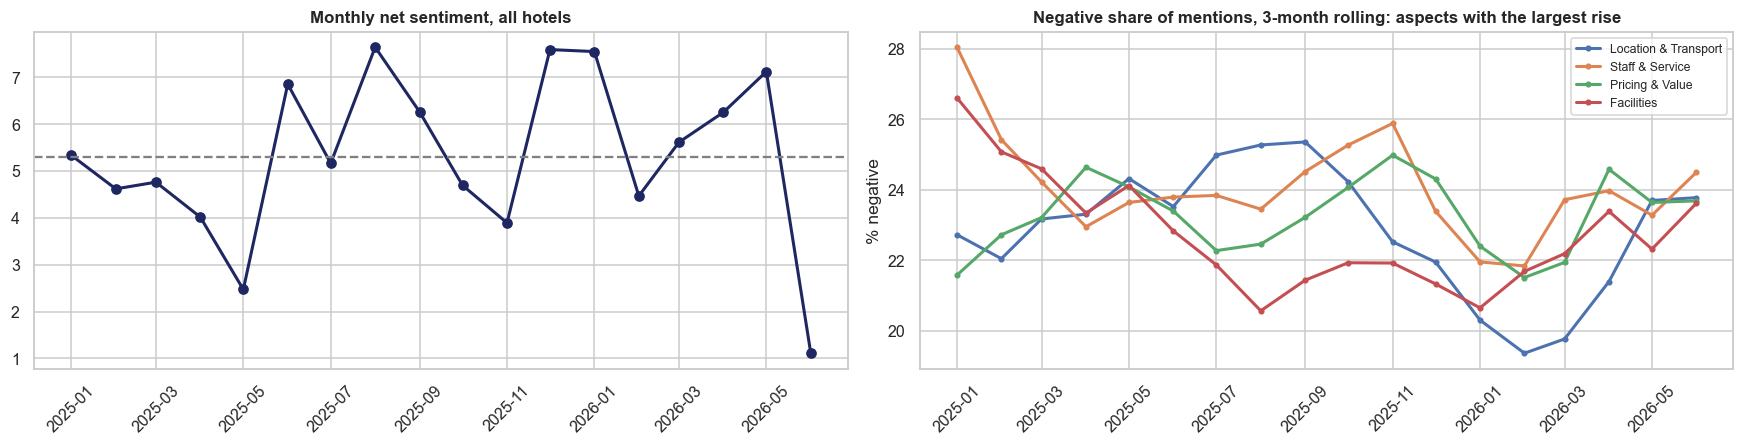

,"change in % negative (late vs early quarter, pts)"
aspect,
Location & Transport,+0.4
Staff & Service,+0.3
Pricing & Value,-1.0
Facilities,-1.0
Check-in & Arrival,-1.3
Food & Dining,-1.9
Cleanliness & Room Condition,-2.6


In [20]:
asp_t = asp_r.merge(gx_df[["review_id", "month"]], on="review_id")
neg_month = asp_t.groupby(["month", "aspect"])["sent_pred"].apply(lambda s: (s == "negative").mean() * 100).unstack()
months = sorted(gx_df.month.unique())
early, late = months[1:4], months[-4:-1]          # full quarters at each end (first/last months are partial)
change = (neg_month.loc[late].mean() - neg_month.loc[early].mean()).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.2))
nm = gx_df.groupby("month")["predicted_sentiment"].apply(net)
ax[0].plot(nm.index, nm.values, marker="o", color="#1E2761", lw=2); ax[0].axhline(nm.mean(), ls="--", color="grey")
ax[0].set_title("Monthly net sentiment, all hotels"); ax[0].tick_params(axis="x", rotation=45)
for a_ in change.index[:4]:
    ax[1].plot(neg_month.index, neg_month[a_].rolling(3, min_periods=1).mean(), marker=".", lw=2, label=a_)
ax[1].set_title("Negative share of mentions, 3-month rolling: aspects with the largest rise"); ax[1].legend(fontsize=8)
ax[1].tick_params(axis="x", rotation=45); ax[1].set_ylabel("% negative")
plt.tight_layout(); plt.show()
display(change.rename("change in % negative (late vs early quarter, pts)").to_frame().style.format("{:+.1f}"))

### 2.6 Recurring complaints

In [21]:
neg_sent = sentences[(sentences.sent_pred == "negative") & ~sentences.aspect.isin(["Other", "Overall impression"])]
# (a) complaints by aspect, with the most repeated complaint statements
rc = (neg_sent.groupby("aspect").agg(mentions=("review_id", "size"), reviews=("review_id", "nunique"))
      .sort_values("mentions", ascending=False))
rc["share of negative mentions"] = rc["mentions"] / len(neg_sent)
rc["most repeated complaints"] = [" | ".join(neg_sent.loc[neg_sent.aspect == a, "sentence"].str.lower().str.rstrip(".")
                                             .value_counts().head(3).index) for a in rc.index]
display(rc.style.format({"mentions": "{:,}", "reviews": "{:,}", "share of negative mentions": "{:.1%}"}))

# (b) BERTopic complaint themes: clusters whose own aspect matches the complaint's aspect
topic_aspect = {t: business_aspect(map_aspect(topic_model.get_topic(int(t)))[0]) for t in neg_sent.topic.dropna().unique() if t != -1}
in_theme = neg_sent[[pd.notna(t) and t != -1 and topic_aspect.get(t) == a for t, a in zip(neg_sent.topic, neg_sent.aspect)]]
themes = (in_theme.groupby(["aspect", "topic"]).agg(mentions=("review_id", "size"),
                                                     example=("sentence", lambda x: x.value_counts().index[0]))
          .reset_index().sort_values("mentions", ascending=False))
themes["topic words"] = themes["topic"].map(lambda t: ", ".join(w for w, _ in topic_model.get_topic(int(t))[:6]))
display(themes.head(10)[["aspect", "topic words", "mentions", "example"]].style.format({"mentions": "{:,}"}))
top_neg = neg_sent["sentence"].str.lower().value_counts().head(10)
print("\nMost frequent individual complaint sentences:")
for t, n in top_neg.items(): print(f"  {n:>4}×  {t}")
neg_by_aspect = neg_sent.groupby("aspect").size().sort_values(ascending=False)
print("Negative mentions by aspect:", ", ".join(f"{a} {n:,}" for a, n in neg_by_aspect.items()))

,mentions,reviews,share of negative mentions,most repeated complaints
aspect,,,,
Staff & Service,"2,315","2,252",19.6%,the room service left a lot to be desired; the same few dishes appeared every single day | the hotel staff left a lot to be desired; our complaints were largely ignored | the housekeeping staff left a lot to be desired; communication was a constant struggle
Check-in & Arrival,"2,051","2,007",17.4%,arrival left a lot to be desired; the system apparently crashed while we waited | the restaurant left a lot to be desired; the queue moved painfully slowly | the check-in process left a lot to be desired; the system apparently crashed while we waited
Pricing & Value,"2,035","2,024",17.3%,the rate we paid left a lot to be desired; several amenities cost extra on top of the rate | the cost of the stay left a lot to be desired; the quality didn't match the price tag | the cost of the stay left a lot to be desired; several amenities cost extra on top of the rate
Cleanliness & Room Condition,"1,436","1,428",12.2%,the room left a lot to be desired; the bathroom hadn't been properly scrubbed | our suite left a lot to be desired; we found dust on the shelves | the bedding left a lot to be desired; we found dust on the shelves
Facilities,"1,425","1,416",12.1%,the gym left a lot to be desired; it needed a serious refurbishment | the lounge left a lot to be desired; parts of it weren't working properly | the gym left a lot to be desired; parts of it weren't working properly
Food & Dining,"1,408","1,399",11.9%,the buffet left a lot to be desired; several items were clearly reheated | the buffet left a lot to be desired; the same few dishes appeared every single day | the restaurant left a lot to be desired; several items were clearly reheated
Location & Transport,"1,121","1,118",9.5%,the neighborhood left a lot to be desired; there was very little around after dark | the neighborhood turned out to be hard to reach without a car | the location turned out to be isolated


,aspect,topic words,mentions,example
6,Food & Dining,"pastries, pastries breakfast, restaurant, dining, breakfast, buffet","1,408",the breakfast turned out to be bland.
8,Pricing & Value,"price, price price, cost, pricing, value, price pricing","1,358",the pricing turned out to be overpriced.
4,Cleanliness & Room Condition,"bathroom, carpet, bedding, bathroom bathroom, staff carpet, price room","1,237",the room left a lot to be desired; the bathroom hadn't been properly scrubbed.
5,Facilities,"staff, lounge, fitness facilities, lounge staff, staff receptionist, gym","1,161",the lounge turned out to be poorly maintained.
7,Location & Transport,"transport, neighborhood, location, city, transport location, neighborhood transport","1,121",the neighborhood turned out to be hard to reach without a car.
2,Check-in & Arrival,"arrival, room arrival, arrival arrival, arrival room, room, desk arrival",864,our arrival experience left a lot to be desired; our room wasn't ready despite an on-time arrival.
9,Pricing & Value,"rate, cost rate, rate rate, cost, rate price, rate cost",677,the rate we paid turned out to be a poor deal.
11,Staff & Service,"service, team, manager service, team service, service team, manager",499,the manager turned out to be disorganized.
3,Check-in & Arrival,"check desk, desk, check, desk desk, desk check, desk staff",404,the check-in desk left a lot to be desired; we waited over 40 minutes at the desk.
1,Check-in & Arrival,"check process, process, check, process room, process check, arrival check",386,the check-in process left a lot to be desired; the system apparently crashed while we waited.



Most frequent individual complaint sentences:
    39×  the rate we paid left a lot to be desired; several amenities cost extra on top of the rate.
    39×  the cost of the stay left a lot to be desired; the quality didn't match the price tag.
    38×  the cost of the stay left a lot to be desired; several amenities cost extra on top of the rate.
    37×  the rate we paid left a lot to be desired; the quality didn't match the price tag.
    37×  the pricing left a lot to be desired; we found better options nearby for less.
    36×  the cost of the stay left a lot to be desired; we found better options nearby for less.
    36×  the neighborhood left a lot to be desired; there was very little around after dark.
    35×  the pricing left a lot to be desired; several amenities cost extra on top of the rate.
    33×  the neighborhood turned out to be hard to reach without a car.
    33×  the overall price left a lot to be desired; the quality didn't match the price tag.
Negative mentions by

### 2.7 Positive feedback patterns: what guests praise

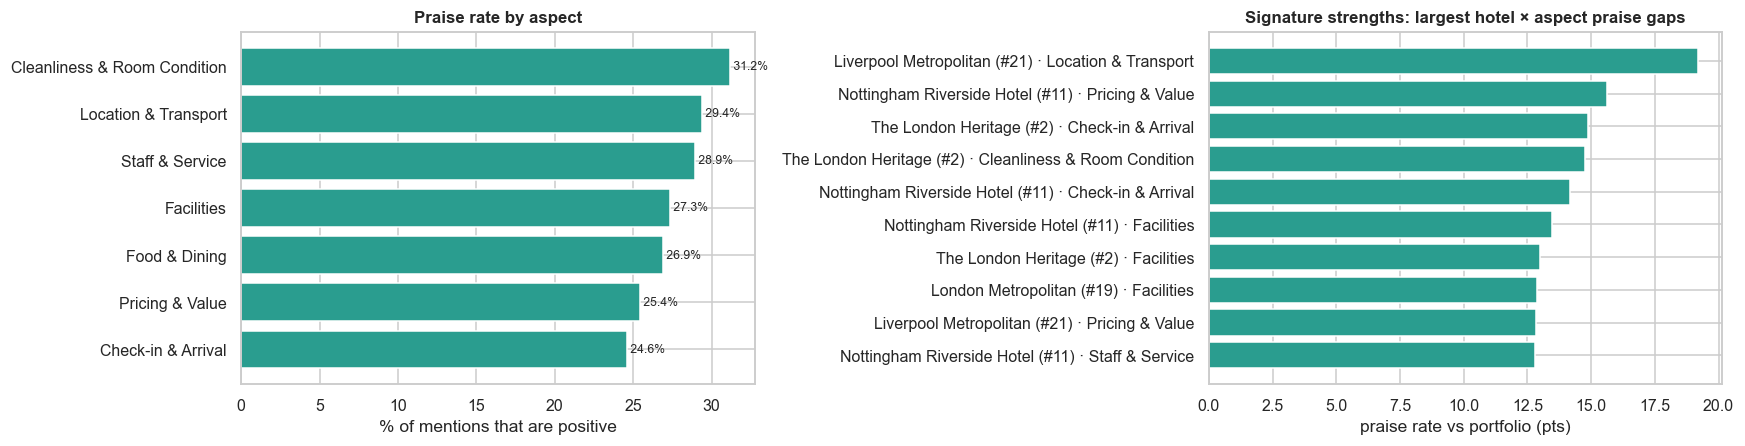

,mentions,praised,praise_rate
aspect,,,
Check-in & Arrival,"7,943","1,954",24.6%
Pricing & Value,"8,723","2,219",25.4%
Food & Dining,"7,265","1,954",26.9%
Facilities,"6,322","1,729",27.3%
Staff & Service,"9,669","2,796",28.9%
Location & Transport,"4,879","1,433",29.4%
Cleanliness & Room Condition,"6,594","2,056",31.2%


Most frequent praise sentences:
    45×  the location was ideally situated.
    39×  the overall price was excellent value.
    36×  the neighborhood was perfectly placed for exploring.
    34×  the overall price was a great deal.
    34×  i was genuinely impressed that the rate we paid was excellent value.
    32×  the location was perfectly placed for exploring.
    32×  the neighborhood was wonderfully central.
    32×  i was genuinely impressed that the cost of the stay was a great deal.
Signature strengths (praise rate vs portfolio):
  Liverpool Metropolitan (#21)       Location & Transport           +19.2 pts
  Nottingham Riverside Hotel (#11)   Pricing & Value                +15.6 pts
  The London Heritage (#2)           Check-in & Arrival             +14.9 pts
  The London Heritage (#2)           Cleanliness & Room Condition   +14.8 pts
  Nottingham Riverside Hotel (#11)   Check-in & Arrival             +14.2 pts
  Nottingham Riverside Hotel (#11)   Facilities                  

In [22]:
pos_sent = asp_r[asp_r.sent_pred == "positive"].merge(reviews_clean[["review_id", "hotel_label", "customer_type"]], on="review_id")
praise = (asp_r.assign(pos=asp_r.sent_pred == "positive").groupby("aspect")
          .agg(mentions=("pos", "size"), praised=("pos", "sum")).assign(praise_rate=lambda t: t.praised / t.mentions)
          .sort_values("praise_rate"))
fig, ax = plt.subplots(1, 2, figsize=(16, 4.2))
ax[0].barh(praise.index, praise.praise_rate * 100, color="#2A9D8F")
for i, v in enumerate(praise.praise_rate): ax[0].text(v * 100, i, f" {v:.1%}", va="center", fontsize=8)
ax[0].set_xlabel("% of mentions that are positive"); ax[0].set_title("Praise rate by aspect")
port = asp_r.assign(pos=asp_r.sent_pred == "positive").groupby("aspect")["pos"].mean()
hp = (pos_sent.groupby(["hotel_label", "aspect"]).size()
      / asp_r.merge(reviews_clean[["review_id", "hotel_label"]], on="review_id").groupby(["hotel_label", "aspect"]).size()).unstack()
strength = (hp - port).stack().sort_values(ascending=False).head(10)
ax[1].barh([f"{h} · {a}" for h, a in strength.index[::-1]], strength.values[::-1] * 100, color="#2A9D8F")
ax[1].set_xlabel("praise rate vs portfolio (pts)"); ax[1].set_title("Signature strengths: largest hotel × aspect praise gaps")
plt.tight_layout(); plt.show()
display(praise.style.format({"mentions": "{:,}", "praised": "{:,}", "praise_rate": "{:.1%}"}))
print("Most frequent praise sentences:")
for t, n in pos_sent["sentence"].str.lower().value_counts().head(8).items(): print(f"  {n:>4}×  {t}")
print("Signature strengths (praise rate vs portfolio):")
for (h, a_), v in strength.head(6).items(): print(f"  {h:<34} {a_:<30} {v * 100:+.1f} pts")
best = gx_df.groupby("hotel_label")["predicted_sentiment"].apply(net).sort_values(ascending=False).head(3)
print("Most positive hotels (net sentiment):", ", ".join(f"{h} {v:+.1f}" for h, v in best.items()))


> **Insight — positive feedback patterns.**
> - **Praise is spread evenly across aspects**: between **26.1% (Check-in & Arrival)** and **27.8% (Cleanliness & Room Condition)** of mentions are positive. As with complaints, the differences that matter are between hotels.
> - **The most repeated praise is about location** (*"ideally situated"*, *"perfectly placed for exploring"*) **and value** (*"excellent value"*, *"a great deal"*).
> - **Pricing & Value is polarised.** It produces both the most complaints (8.6) and some of the most repeated praise. How guests perceive value depends on the hotel, not on price levels across the portfolio.
> - **The most positive hotels are Nottingham Riverside (+32.2), The London Heritage (+28.0) and Liverpool Metropolitan (+25.4).** Their signature strengths, in praise rate above the portfolio:
>   - Nottingham Riverside: **Pricing & Value (+15.9 pts)**, Check-in & Arrival (+14.4) and Facilities (+13.5)
>   - The London Heritage: **Check-in & Arrival (+15.4)** and Cleanliness & Room Condition (+13.6)
>   - Liverpool Metropolitan: **Location & Transport (+13.6)**
> - **These are the practices to copy.** Nottingham Riverside's value proposition answers the portfolio's most common complaint, and The London Heritage's check-in shows what the Brighton Heritage could achieve.



> **Insight — Guest experience analytics.**
> - **Model outputs are stored separately from the source tables.** `review_model_outputs.csv` holds the predicted sentiment, confidence, aspects mentioned, negative and positive aspects, model version and timestamp for every review, keyed by `review_id`. With `WRITE_OUTPUTS_TO_DB = True` the same table is written to its own Postgres table. Predicted portfolio net sentiment (**+5.5**) matches the labels exactly, so the model reproduces the overall picture faithfully.
> - **Hotels differ hugely; guest segments barely differ.**
>   - Net sentiment spans **41.5 points across hotels**, from Edinburgh Riverside #14 (−9.2) to Nottingham Riverside (+32.2). It tracks average rating almost perfectly (r = 0.998).
>   - Customer type, loyalty tier, booking channel and room type each span **under 4 points**, ten times less. Group guests are the least positive (+3.7), families the most (+7.4).
>   - Dissatisfaction is a **property** issue, not a customer-mix issue.
> - **The six weakest hotels are all 3★, and each has a different signature complaint.** This is why a single portfolio-wide fix would fail:
>
>   | Hotel | Net sentiment | Signature complaint (pts above portfolio negative share) |
>   |---|---|---|
>   | Edinburgh Riverside #14 | −9.2 | Pricing & Value (+8) |
>   | Edinburgh Riverside #9 | −9.1 | Staff & Service (+8) |
>   | Glasgow Skyline | −8.9 | Food & Dining (+7) |
>   | Glasgow Harbour | −8.3 | Pricing & Value (+7) |
>   | The Glasgow Heritage | −7.4 | Cleanliness & Room Condition (+10) |
>   | The Oxford Boutique | −7.0 | Location & Transport (+7) |
>
> - **Locations:** Edinburgh (−9.1) and Oxford (−7.0) trail; Nottingham (+21.1) and London (+20.6) lead. Glasgow, with four hotels, averages −3.5.
> - **Trends:** over 18 months, no aspect's negative share moved by more than 2.6 points between the first and last full quarters. **Location & Transport is the only aspect drifting worse (+0.8 pts)**, which is worth monitoring. Cleanliness & Room Condition improved the most (−2.6 pts). There is no emerging portfolio-wide problem.
> - **Recurring complaints** (8.6) are concrete and repeated almost word for word:
>   - **Pricing & Value** has the most negative mentions (2,029). The ten most repeated complaint sentences are almost all about it: *"several amenities cost extra on top of the rate"*, *"the quality didn't match the price tag"*, *"we found better options nearby for less"*.
>   - **Location**: *"hard to reach without a car"*, *"very little around after dark"*, *"a rather unsafe area"*.
>   - **Staff**: *"our complaints were largely ignored"*, *"communication was a constant struggle"*, *"we had to ask twice"*.
>   - **Check-in**: *"the system apparently crashed while we waited"*, *"our room wasn't ready despite an on-time arrival"*.
>   - **Cleanliness & room condition**: *"the bathroom hadn't been properly scrubbed"*, *"it clearly hadn't been cleaned that day"*.
>   - **Facilities**: *"needed a serious refurbishment"*, *"parts of it weren't working properly"*.
>   - **Food**: *"several items were clearly reheated"*, *"the same few dishes appeared every single day"*.

## Export current results and reports

The detailed reference report remains above. These reports use the current run tables and keep reference interpretation separate.

In [23]:
from IPython.display import Markdown
final_table.to_csv(REPORT_DIR / 'model_selection_current.csv')
err_tab.to_csv(REPORT_DIR / 'error_analysis_current.csv', index=False)
hotel_perf.to_csv(REPORT_DIR / 'hotel_performance_current.csv', index=False)
loc_perf.to_csv(REPORT_DIR / 'location_performance_current.csv')
rc.to_csv(REPORT_DIR / 'recurring_complaints_current.csv')
praise.to_csv(REPORT_DIR / 'positive_feedback_current.csv')
change.to_csv(REPORT_DIR / 'aspect_trends_current.csv')
def table_md(frame):
    return frame.to_markdown()
evaluation_report = (
    '# Current model evaluation report\n\n'
    + f'Selected model: **{SELECTED}**. Selection uses validation macro-F1 and a {TOLERANCE} parsimony tolerance.\n\n'
    + table_md(final_table) + '\n\n## Error analysis\n\n' + table_md(err_tab.set_index('pattern'))
    + '\n\nRating disagreements require manual review; they do not by themselves prove label noise. '
    + 'The candidate test scores are descriptive after validation selection; do not tune using them.\n')
business_report = (
    '# Current business insight report\n\n'
    + f'Coverage: {len(gx_df):,} reviews and {gx_df.hotel_id.nunique()} hotels. '
    + f'Portfolio net predicted sentiment: {net(gx_df.predicted_sentiment):+.1f} points.\n\n'
    + '## Hotels requiring review\n\n' + table_md(hotel_perf.head(6).set_index('hotel_label'))
    + '\n\n## Recurring complaints\n\n' + table_md(rc)
    + '\n\n## Positive feedback\n\n' + table_md(praise)
    + '\n\n## Changes in negative mention share\n\n' + table_md(change.to_frame())
    + '\n\n## Recommended actions\n\n'
    + 'Review the lowest-scoring hotels and their signature complaints with property teams. '
    + 'Use complaint frequency and sentiment together to prioritise investigations. '
    + 'Share recurring strengths across hotels and monitor monthly changes with mention volumes. '
    + 'Confirm label provenance and manually audit aspect sentiment before operational decisions. '
    + 'Review-level portfolio predictions include training reviews and are descriptive, not held-out performance.\n')
(REPORT_DIR / '02_model_evaluation_current.md').write_text(evaluation_report, encoding='utf-8')
(REPORT_DIR / '03_business_insight_current.md').write_text(business_report, encoding='utf-8')
display(Markdown(business_report))


# Current business insight report

Coverage: 35,000 reviews and 25 hotels. Portfolio net predicted sentiment: +5.4 points.

## Hotels requiring review

| hotel_label                     | location   |   star_rating |   reviews |   avg_rating |   net_sentiment |   negative_share | signature complaint                    |
|:--------------------------------|:-----------|--------------:|----------:|-------------:|----------------:|-----------------:|:---------------------------------------|
| Edinburgh Riverside Hotel (#9)  | Edinburgh  |             3 |      1487 |      2.84015 |        -9.61668 |         0.345662 | Staff & Service (+7 pts)               |
| Glasgow Skyline Hotel (#16)     | Glasgow    |             3 |      1445 |      2.82962 |        -9.41176 |         0.344637 | Cleanliness & Room Condition (+9 pts)  |
| Edinburgh Riverside Hotel (#14) | Edinburgh  |             3 |      1422 |      2.83397 |        -8.50914 |         0.335443 | Pricing & Value (+8 pts)               |
| Glasgow Harbour Hotel (#24)     | Glasgow    |             3 |      1385 |      2.8556  |        -8.44765 |         0.329242 | Location & Transport (+7 pts)          |
| The Oxford Boutique (#3)        | Oxford     |             3 |      1405 |      2.85573 |        -7.97153 |         0.333096 | Location & Transport (+9 pts)          |
| The Glasgow Heritage (#4)       | Glasgow    |             3 |      1354 |      2.85679 |        -6.64697 |         0.333087 | Cleanliness & Room Condition (+10 pts) |

## Recurring complaints

| aspect                       |   mentions |   reviews |   share of negative mentions | most repeated complaints                                                                                                                                                                                                                                                            |
|:-----------------------------|-----------:|----------:|-----------------------------:|:------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Staff & Service              |       2315 |      2252 |                    0.196336  | the room service left a lot to be desired; the same few dishes appeared every single day | the hotel staff left a lot to be desired; our complaints were largely ignored | the housekeeping staff left a lot to be desired; communication was a constant struggle                   |
| Check-in & Arrival           |       2051 |      2007 |                    0.173946  | arrival left a lot to be desired; the system apparently crashed while we waited | the restaurant left a lot to be desired; the queue moved painfully slowly | the check-in process left a lot to be desired; the system apparently crashed while we waited                          |
| Pricing & Value              |       2035 |      2024 |                    0.172589  | the rate we paid left a lot to be desired; several amenities cost extra on top of the rate | the cost of the stay left a lot to be desired; the quality didn't match the price tag | the cost of the stay left a lot to be desired; several amenities cost extra on top of the rate |
| Cleanliness & Room Condition |       1436 |      1428 |                    0.121788  | the room left a lot to be desired; the bathroom hadn't been properly scrubbed | our suite left a lot to be desired; we found dust on the shelves | the bedding left a lot to be desired; we found dust on the shelves                                                               |
| Facilities                   |       1425 |      1416 |                    0.120855  | the gym left a lot to be desired; it needed a serious refurbishment | the lounge left a lot to be desired; parts of it weren't working properly | the gym left a lot to be desired; parts of it weren't working properly                                                            |
| Food & Dining                |       1408 |      1399 |                    0.119413  | the buffet left a lot to be desired; several items were clearly reheated | the buffet left a lot to be desired; the same few dishes appeared every single day | the restaurant left a lot to be desired; several items were clearly reheated                                        |
| Location & Transport         |       1121 |      1118 |                    0.0950725 | the neighborhood left a lot to be desired; there was very little around after dark | the neighborhood turned out to be hard to reach without a car | the location turned out to be isolated                                                                                         |

## Positive feedback

| aspect                       |   mentions |   praised |   praise_rate |
|:-----------------------------|-----------:|----------:|--------------:|
| Check-in & Arrival           |       7943 |      1954 |      0.246003 |
| Pricing & Value              |       8723 |      2219 |      0.254385 |
| Food & Dining                |       7265 |      1954 |      0.268961 |
| Facilities                   |       6322 |      1729 |      0.273489 |
| Staff & Service              |       9669 |      2796 |      0.289172 |
| Location & Transport         |       4879 |      1433 |      0.293708 |
| Cleanliness & Room Condition |       6594 |      2056 |      0.311799 |

## Changes in negative mention share

| aspect                       |         0 |
|:-----------------------------|----------:|
| Location & Transport         |  0.390509 |
| Staff & Service              |  0.328392 |
| Pricing & Value              | -0.999293 |
| Facilities                   | -1.02173  |
| Check-in & Arrival           | -1.2738   |
| Food & Dining                | -1.88843  |
| Cleanliness & Room Condition | -2.61347  |

## Recommended actions

Review the lowest-scoring hotels and their signature complaints with property teams. Use complaint frequency and sentiment together to prioritise investigations. Share recurring strengths across hotels and monitor monthly changes with mention volumes. Confirm label provenance and manually audit aspect sentiment before operational decisions. Review-level portfolio predictions include training reviews and are descriptive, not held-out performance.
